### Import libraries

In [1]:
import os
import sys
import jiwer
import json
import time
from collections import defaultdict
from functools import partial
from pathlib import Path

REPO_ROOT = Path(os.getcwd()).resolve().parent
LEADERBOARD = REPO_ROOT / "open_asr_leaderboard"
assert (LEADERBOARD / "normalizer" / "__init__.py").is_file(), (
    f"{LEADERBOARD} is empty — run: git submodule update --init --recursive"
)
for p in (REPO_ROOT, LEADERBOARD):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

LOCAL_DATA_ROOT = REPO_ROOT / "data"

# Must precede any huggingface import — the cache path is resolved at import time, and
# the weights live under data/hub, not ~/.cache.
os.environ["HF_HOME"] = str(LOCAL_DATA_ROOT)

import torch
from torch import nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from torchmetrics import Metric
from transformers import WhisperTokenizerFast
from torch.utils.data import DataLoader, Dataset, Subset, random_split
from kaldialign import batch_error_rate

from normalizer import data_utils
from models.drax.transformer import Transformer

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

/home/doterog/repos/personal_projects/continuous-flow-asr/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Set HPs

In [2]:
REPO_ID = "openslr/librispeech_asr"
CONFIG = "clean"
SPLIT = "train.100"
DEFAULT_MODEL = "openai/whisper-large-v3"


SUBSET_N = 2000
CANVAS_LEN = 96
# mean-pool 1500 encoder frames -> 375, i.e. 20ms -> 80ms
AUDIO_STRIDE = 4
BS = 32
MODEL_DIM = 256
MODEL_BLOCKS = 4
MODEL_HEADS = 4
COND_DIM = 64
MU_BLOCKS = 2
COMPACT_VOCAB = True

### Load dataset

In [3]:
audio_feature_dir = (
    LOCAL_DATA_ROOT /
    "features" /
    DEFAULT_MODEL.split("/")[-1] /
    CONFIG /
    SPLIT
)

class AudioFeatureDataset(Dataset):
    """Utterance-level view over the sharded (frames, d_model) feature files.

    The split is ~103 GB on disk, so the .npy shards stay memory-mapped and only the
    requested slice is copied into RAM; the OS page cache keeps hot shards resident.
    The .json indexes are small, so they are read once up front and flattened into a
    single utterance table (shards are not all the same size, so idx can't be split
    arithmetically).
    """

    def __init__(self, audio_feature_dir: Path):
        self.index_paths = sorted(audio_feature_dir.glob("*.json"))
        assert self.index_paths, f"no feature shards under {audio_feature_dir}"

        self.utts = []  # (shard_idx, offset, length, text)
        for shard_idx, index_path in enumerate(self.index_paths):
            index = json.loads(index_path.read_text())
            self.utts += [
                (shard_idx, u["offset"], u["length"], u["text"]) for u in index["utts"]
            ]
        self.d_model = index["d_model"]
        # Whisper's decoder cross-attends over all 1500 frames, so the cache must be the
        # untrimmed one; a trimmed cache would silently give 1:1-unusable short latents.
        assert not index["trimmed"], f"{audio_feature_dir} holds trimmed latents"
        self._shards = {}  # opened lazily so each DataLoader worker gets its own mmap

    def __len__(self):
        return len(self.utts)

    def _feats(self, shard_idx: int) -> np.ndarray:
        if shard_idx not in self._shards:
            path = self.index_paths[shard_idx].with_suffix(".npy")
            self._shards[shard_idx] = np.load(path, mmap_mode="r")
        return self._shards[shard_idx]

    def __getitem__(self, idx):
        shard_idx, offset, length, text = self.utts[idx]
        feats = self._feats(shard_idx)[offset:offset + length]
        return {
            # copy off the read-only mmap so the tensor owns its memory
            "audio": torch.from_numpy(np.array(feats)),
            "text": text,
        }


class VocabMap:
    """Lossless remap of the Whisper ids that occur in the corpus onto [0, size).

    LibriSpeech is uppercase and unpunctuated, so it touches 1,187 of Whisper's 51,866
    tokens. The other 97.7% are slots the simplex has to carry and the model can never
    use. Dropping them is exact — every id round-trips — and it is what makes a
    (B, L, V) field affordable on a laptop.
    """

    def __init__(self, texts, tokenizer):
        used = sorted({i for ids in tokenizer(texts).input_ids for i in ids})
        self.to_full = torch.tensor(used, dtype=torch.long)
        rev = torch.full((len(tokenizer),), -1, dtype=torch.long)
        rev[self.to_full] = torch.arange(len(used))
        self.to_compact = rev
        self.size = len(used)

    def encode(self, ids):
        out = self.to_compact.to(ids.device)[ids]
        assert (out >= 0).all(), "token outside the compact vocabulary"
        return out

    def decode(self, ids):
        return self.to_full.to(ids.device)[ids]



def collate(batch, tokenizer: WhisperTokenizerFast, canvas_len: int, vocab_map=None):
    """Tokenize onto the fixed canvas and stack the (frames, d_model) latents.

    The flow denoises a whole CANVAS_LEN-wide field at once, so the target width has to
    be identical every batch — at sampling time there is no reference transcript to size
    it from. Padding is <|endoftext|> (Whisper's pad_token_id) and it is a real target:
    the model learns to emit it, which is how a non-autoregressive sample knows where to
    stop. That is also why nothing here builds an attention mask — every canvas position
    is predicted, so there is nothing to exclude.
    """
    enc = tokenizer(
        [b["text"] for b in batch],
        return_tensors="pt",
        padding="max_length",
        truncation=True,
        max_length=canvas_len,
    )
    tokens = enc.input_ids
    if vocab_map is not None:
        tokens = vocab_map.encode(tokens)

    # every clip is 1500 frames now that the cache is untrimmed, so a plain stack does it
    audio = torch.stack([b["audio"] for b in batch])
    if AUDIO_STRIDE > 1:
        # mean-pool along time. Whisper frames are 20 ms; stride 4 makes them 80 ms,
        # still well under a phoneme, and it cuts the cross-attention keys 4x.
        B, T, D = audio.shape
        audio = audio.view(B, T // AUDIO_STRIDE, AUDIO_STRIDE, D).mean(dim=2)

    return {"audio": audio, "tokens": tokens}


audio_ds = AudioFeatureDataset(audio_feature_dir)

tokenizer = WhisperTokenizerFast.from_pretrained(
    DEFAULT_MODEL, language="english", task="transcribe"
)

# One tokenization pass over the whole split serves both the vocab map and the length
# filter, so the subset never contains an utterance the canvas would truncate.
all_texts = [u[3] for u in audio_ds.utts]
all_lens = np.array([len(x) for x in tokenizer(all_texts).input_ids])

if COMPACT_VOCAB:
    VOCAB_MAP = VocabMap(all_texts, tokenizer)
    VOCAB_SIZE = VOCAB_MAP.size
    PAD_ID = VOCAB_MAP.to_compact[tokenizer.pad_token_id].item()
else:
    VOCAB_MAP = None
    VOCAB_SIZE = len(tokenizer)
    PAD_ID = tokenizer.pad_token_id

eligible = np.flatnonzero(all_lens <= CANVAS_LEN)
if SUBSET_N is not None and SUBSET_N < len(eligible):
    eligible = np.random.default_rng(0).choice(eligible, SUBSET_N, replace=False)
work_ds = Subset(audio_ds, sorted(eligible.tolist()))

collate_fn = partial(
    collate, tokenizer=tokenizer, canvas_len=CANVAS_LEN, vocab_map=VOCAB_MAP
)
loader = DataLoader(
    work_ds, batch_size=BS, shuffle=True, num_workers=4, collate_fn=collate_fn
)

batch = next(iter(loader))
print(f"vocab {len(tokenizer):,} -> {VOCAB_SIZE:,}   canvas {CANVAS_LEN}   "
      f"audio stride {AUDIO_STRIDE}   batch {BS}")
print(f"working set {len(work_ds):,} of {len(audio_ds):,} utterances")
print(f"simplex field {BS * CANVAS_LEN * VOCAB_SIZE * 4 / 2**20:.1f} MiB/tensor "
      f"(was {8 * 160 * len(tokenizer) * 4 / 2**20:.0f} MiB at B=8 full-vocab)")
{k: tuple(v.shape) for k, v in batch.items()}

vocab 51,866 -> 1,187   canvas 96   audio stride 4   batch 32
working set 2,000 of 28,539 utterances
simplex field 13.9 MiB/tensor (was 253 MiB at B=8 full-vocab)


{'audio': (32, 375, 1280), 'tokens': (32, 96)}

### Define Evaluation and Assess Linear Interpolant Corruption

In [10]:
PREFIX_LEN = 4  # <|startoftranscript|><|en|><|transcribe|><|notimestamps|>


def ids_to_text(ids, tokenizer, pad_id, vocab_map="default"):
    """Canvas token ids -> transcripts, cut at the first <|endoftext|> after the prefix.

    Cutting rather than relying on skip_special_tokens alone: an untrained model emits
    tokens all over the canvas, and everything past the first end-of-text is not part of
    the transcript a sampler would have produced.
    """
    if vocab_map == "default":
        vocab_map = VOCAB_MAP  # compact ids have to become Whisper ids before decoding
    if vocab_map is not None:
        ids = vocab_map.decode(ids)
        pad_id = vocab_map.to_full[pad_id].item()

    texts = []
    for row in ids.tolist():
        tail = row[PREFIX_LEN:]
        if pad_id in tail:
            row = row[: PREFIX_LEN + tail.index(pad_id)]
        texts.append(
            tokenizer.decode(row, skip_special_tokens=True, clean_up_tokenization_spaces=False)
        )
    return texts


def edit_counts(ref: str, pred: str) -> tuple[int, int]:
    """(errors, reference words) for one already-normalized pair, as score_results counts.

    kaldialign with merge_compounds=True, not jiwer. This is what the leaderboard scores
    with, and it forgives split compounds in either direction — "white paper" vs
    "whitepaper" is 0 errors here and 33% under jiwer. score_eval.py prints a jiwer
    column too, but only as a cross-check against the pre-kaldialign CSV; the kaldialign
    column is the one --expect asserts on and the one the published figures came from.
    """
    r = batch_error_rate([tuple(ref.split())], [tuple(pred.split())], merge_compounds=True)
    return r["total"], r["ref_len"]


def wer(refs: list[str], preds: list[str]) -> float:
    """Percent corpus WER, the way scripts/score_eval.py's kaldialign column computes it.

    Whisper's EnglishTextNormalizer folds case, strips punctuation, expands contractions
    and rewrites number words as digits, so it must be applied to both sides — and never
    to the training targets, which stay raw.
    """
    pairs = [
        (data_utils.normalizer(r), data_utils.normalizer(p))
        for r, p in zip(refs, preds, strict=True)
    ]
    # An empty reference has no words to divide by; the leaderboard drops them at write
    # time, and kaldialign reports err_rate=inf for one.
    pairs = [(r, p) for r, p in pairs if r.strip()]
    r = batch_error_rate(
        [tuple(r.split()) for r, _ in pairs],
        [tuple(p.split()) for _, p in pairs],
        merge_compounds=True,
    )
    return 100 * r["err_rate"]


class BinnedWER(Metric):
    """Corpus WER as a function of the flow time t, in equal-width bins.

    Accumulates edit counts rather than per-utterance rates. Corpus WER is
    sum(errors)/sum(ref_words) — averaging per-utterance WERs is a different number, and
    would let a three-word utterance weigh as much as a thirty-word one. Summing the
    counts and dividing at the end is exactly equal to scoring a whole bin in one call,
    but costs two floats per bin instead of every string seen in the epoch.
    """

    def __init__(self, tokenizer, pad_id, num_bins=10, **kwargs):
        super().__init__(**kwargs)
        self.tokenizer = tokenizer
        self.pad_id = pad_id
        self.num_bins = num_bins
        self.add_state("errors", default=torch.zeros(num_bins), dist_reduce_fx="sum")
        self.add_state("ref_words", default=torch.zeros(num_bins), dist_reduce_fx="sum")

    def _bin_indices(self, t):
        return (t * self.num_bins).long().clamp(min=0, max=self.num_bins - 1)

    def update(self, pred_ids, target_ids, t):
        """pred_ids, target_ids: (B, L) token ids.  t: (B,) the flow time of each row."""
        preds = ids_to_text(pred_ids, self.tokenizer, self.pad_id)
        refs = ids_to_text(target_ids, self.tokenizer, self.pad_id)

        for b, ref, pred in zip(self._bin_indices(t).tolist(), refs, preds):
            ref, pred = data_utils.normalizer(ref), data_utils.normalizer(pred)
            if not ref.strip():
                continue
            errors, ref_words = edit_counts(ref, pred)
            self.errors[b] += errors
            self.ref_words[b] += ref_words

    def compute(self):
        """(num_bins,) percent WER; empty bins report 0."""
        return 100 * self.errors / self.ref_words.clamp(min=1)

    def overall(self) -> float:
        """Corpus WER across every bin — the number to compare against the harness."""
        total = self.ref_words.sum()
        if total == 0:
            return float("nan")
        return (100 * self.errors.sum() / total).item()

    def bin_edges(self):
        return torch.linspace(0, 1, self.num_bins + 1)


def plot_binned_wer(metric, ax=None, label=None):
    binned = metric.compute().cpu().numpy()
    edges = metric.bin_edges()
    centers = ((edges[:-1] + edges[1:]) / 2).numpy()
    seen = (metric.ref_words > 0).cpu().numpy()  # don't draw bins nothing landed in

    ax = ax or plt.subplots(figsize=(6, 4))[1]
    ax.plot(centers[seen], binned[seen], marker="o", label=label)
    ax.set_xlabel("t (binned)")
    ax.set_ylabel("WER %")
    ax.set_ylim(0, 150)
    ax.grid(alpha=0.3)
    if label:
        ax.legend()
    return ax


# The bin-accumulating path must agree with one corpus call, or a binned number is not
# comparable to what score_eval.py reports.
_r = ["the quick brown fox jumps", "a white paper on flow matching", "hello there general kenobi"]
_p = ["the quick brown ox jumps now", "a whitepaper on flow matching", "hello there general"]
_e, _n = map(sum, zip(*(edit_counts(data_utils.normalizer(r), data_utils.normalizer(p))
                        for r, p in zip(_r, _p))))
print(f"corpus call {wer(_r, _p):.4f}%  ==  accumulated {100 * _e / _n:.4f}%")
print(f"jiwer, for contrast: {100 * jiwer.wer([data_utils.normalizer(r) for r in _r],
                                              [data_utils.normalizer(p) for p in _p]):.4f}%")

corpus call 20.0000%  ==  accumulated 20.0000%
jiwer, for contrast: 33.3333%


In [5]:
class BinnedLoss(Metric):
    """Mean per-sequence loss as a function of the flow time t, in equal-width bins.

    The companion to BinnedWER. WER says how much of the transcript came out right; this
    says how hard the objective was. Reading them together separates "the model cannot do
    this" from "x_t carried no information at this t" — which, given the corruption sweep
    above, is the distinction that matters below t ~ 0.8.

    Unlike BinnedWER this costs nothing: no decoding, just a scatter-add, so it is worth
    tracking on training epochs as well as validation ones.
    """

    def __init__(self, num_bins=10, **kwargs):
        super().__init__(**kwargs)
        self.num_bins = num_bins
        self.add_state("loss_sum", default=torch.zeros(num_bins), dist_reduce_fx="sum")
        self.add_state("count", default=torch.zeros(num_bins), dist_reduce_fx="sum")

    def _bin_indices(self, t):
        return (t * self.num_bins).long().clamp(min=0, max=self.num_bins - 1)

    def update(self, per_sequence_loss, t):
        """per_sequence_loss: (B,) — one value per row, NOT the batch mean."""
        idx = self._bin_indices(t)
        loss = per_sequence_loss.detach().float()
        self.loss_sum.scatter_add_(0, idx, loss)
        self.count.scatter_add_(0, idx, torch.ones_like(loss))

    def compute(self):
        """(num_bins,) mean loss; empty bins report 0."""
        return self.loss_sum / self.count.clamp(min=1)

    def overall(self) -> float:
        n = self.count.sum()
        if n == 0:
            return float("nan")
        return (self.loss_sum.sum() / n).item()

    def bin_edges(self):
        return torch.linspace(0, 1, self.num_bins + 1)


def plot_binned_loss(metric, ax=None, label=None, reference_line=None):
    binned = metric.compute().cpu().numpy()
    edges = metric.bin_edges()
    centers = ((edges[:-1] + edges[1:]) / 2).numpy()
    seen = (metric.count > 0).cpu().numpy()

    ax = ax or plt.subplots(figsize=(6, 4))[1]
    ax.plot(centers[seen], binned[seen], marker="o", label=label)
    if reference_line is not None:
        # ln(V) is where an untrained (uniform) model sits — anything at that level means
        # the model is predicting nothing at all in that bin.
        ax.axhline(reference_line, color="k", ls="--", alpha=0.4, label="ln(V), uniform")
    ax.set_xlabel("t (binned)")
    ax.set_ylabel("cross-entropy")
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.3)
    if label or reference_line is not None:
        ax.legend()
    return ax

In [6]:
class BinnedTokenError(Metric):
    """Token error rate P_e(t) per t-bin — the quantity the time reparameterization needs.

    Deliberately token-level, not WER. Eq. 25's |V|/(|V|-1) factor is exactly 1/P_e(0),
    which only holds when P_e(0) = (V-1)/V, the hit rate of an argmax over pure noise.
    WER has no such anchor (insertions push it past 100% on an untrained model), so
    feeding BinnedWER into the reparameterization would drive tau negative.

    Cheap — a comparison and two sums, no decoding — so it can run every epoch and let
    tau be re-estimated from the model rather than from the model-free corruption sweep.
    """

    def __init__(self, num_bins=100, **kwargs):
        super().__init__(**kwargs)
        self.num_bins = num_bins
        self.add_state("errors", default=torch.zeros(num_bins), dist_reduce_fx="sum")
        self.add_state("count", default=torch.zeros(num_bins), dist_reduce_fx="sum")

    def _bin_indices(self, t):
        return (t * self.num_bins).long().clamp(min=0, max=self.num_bins - 1)

    def update(self, pred_ids, target_ids, t):
        idx = self._bin_indices(t)
        wrong = (pred_ids != target_ids).sum(dim=1).float()
        total = torch.full_like(wrong, target_ids.size(1))
        self.errors.scatter_add_(0, idx, wrong)
        self.count.scatter_add_(0, idx, total)

    def compute(self):
        """(num_bins,) P_e; empty bins report 0."""
        return self.errors / self.count.clamp(min=1)

    def recovery(self):
        """(num_bins,) 1 - P_e, i.e. token recovery — what make_tau_inverse consumes."""
        return 1 - self.compute()

    def bin_centers(self):
        edges = torch.linspace(0, 1, self.num_bins + 1)
        return (edges[:-1] + edges[1:]) / 2

    def bin_edges(self):
        return torch.linspace(0, 1, self.num_bins + 1)


def tau_from_recovery(recovery, vocab_size):
    """Eq. 25: tau(t) = 1 - P_e(t)/P_e(0), cumulative decoding progress in [0, 1].

    P_e(0) = (V-1)/V because an argmax over pure noise is right 1/V of the time, so the
    1/P_e(0) here is the paper's |V|/(|V|-1). Forced monotone: tau has to be invertible
    and the measured curve is a finite sample.
    """
    recovery = np.asarray(recovery, dtype=np.float64)
    p_e = 1.0 - recovery
    p_e0 = 1.0 - 1.0 / vocab_size
    tau = np.clip(1.0 - p_e / p_e0, 0.0, 1.0)
    return np.maximum.accumulate(tau)


def make_tau_inverse(ts, recovery, vocab_size, flat_eps=1e-3):
    """Build t = tau^-1(u), the map from a uniform draw to a flow time.

    This is the INVERSE of Eq. 25. The paper samples t such that tau(t) ~ U[0,1], so what
    training and the generation grid both need is u -> t, not t -> tau.

    Two details the naive inversion gets wrong:
      * tau is ~0 across the whole dead zone (t < ~0.65 at Whisper's vocabulary). Keeping
        the LAST t of each flat run makes tau^-1(0) the right edge of that zone instead
        of spreading samples linearly across a region where nothing is decided.
      * a finite sample makes tau wobble by ~1e-4 down there, and those wobbles survive
        the monotone fix as genuine-looking steps; flat_eps clamps them to exactly 0.
    """
    ts = np.asarray(ts, dtype=np.float64)
    tau = tau_from_recovery(recovery, vocab_size)
    tau[tau < flat_eps] = 0.0

    keep = np.concatenate([np.diff(tau) > 0, [True]])  # last index of every flat run
    tau_k, t_k = tau[keep], ts[keep]

    def tau_inverse(u):
        """u: (B,) uniform in [0, 1] -> t: (B,) flow times."""
        is_tensor = torch.is_tensor(u)
        u_np = u.detach().cpu().numpy() if is_tensor else np.asarray(u)
        t_np = np.interp(u_np, tau_k, t_k)
        if not is_tensor:
            return t_np
        return torch.as_tensor(t_np, dtype=u.dtype, device=u.device)

    tau_inverse.tau = tau
    tau_inverse.ts = ts
    tau_inverse.knots = (tau_k, t_k)
    return tau_inverse


def generation_grid(tau_inverse, num_steps):
    """t_n = tau^-1(n/N) — the sampler's schedule, uniform in tau rather than in t.

    Training and generation have to share this. Once the model is trained under the
    reparameterization it has seen almost nothing below the dead zone, so integrating on
    a uniform-in-t grid afterwards would run it far out of distribution.
    """
    return tau_inverse(np.linspace(0.0, 1.0, num_steps + 1))

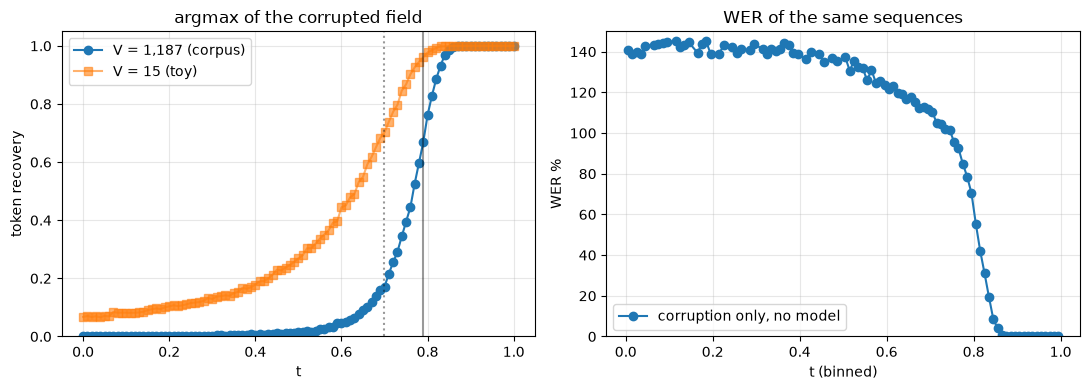

token recovery   t=0.5 0.000   t=0.7 0.001   t=0.8 0.001
argmax threshold V=1,187: t > 0.790   |   V=15: t > 0.699


In [11]:
@torch.no_grad()
def corrupt_and_decode(tokens, vocab_size, t, chunk=8):
    """The interpolant with no model in the loop: argmax of (1-t)*x0 + t*x1.

    Per canvas position the true slot lands at t + (1-t)*N(0,1) and each of the other
    V-1 slots at (1-t)*N(0,1). argmax recovers the token only when the spike beats the
    largest of those V-1 draws, which sits near sqrt(2 ln V) — about 4.2 here.

    Chunked because a (B, 160, 51866) float field is ~132 MB per 4 sequences, and
    randn_like allocates a second one.
    """
    out = []
    for i in range(0, tokens.size(0), chunk):
        x1 = F.one_hot(tokens[i:i + chunk], vocab_size).float()
        out.append(((1 - t) * torch.randn_like(x1) + t * x1).argmax(dim=-1))
    return torch.cat(out)


def sweep_corruption(tokens, vocab_size, ts, tokenizer, pad_id, num_bins=100):
    """How much of the transcript survives pure corruption, as a function of t."""
    metric = BinnedWER(tokenizer, pad_id, num_bins=num_bins).to(tokens.device)
    recovery = []
    for t in ts:
        noisy = corrupt_and_decode(tokens, vocab_size, t)
        recovery.append((noisy == tokens).float().mean().item())
        metric.update(noisy, tokens, torch.full((tokens.size(0),), t, device=tokens.device))
    return metric, recovery


SWEEP_N = 64
NUM_BINS = 100
sweep_texts = [audio_ds.utts[i][3] for i in work_ds.indices[:SWEEP_N]]
sweep_tokens = tokenizer(
    sweep_texts, return_tensors="pt", padding="max_length",
    truncation=True, max_length=CANVAS_LEN,
).input_ids.to(device)

if VOCAB_MAP is not None:
    # the sweep one-hots against VOCAB_SIZE, so it needs compact ids like everything else
    sweep_tokens = VOCAB_MAP.encode(sweep_tokens)

ts = torch.linspace(0.0, 1.0, NUM_BINS + 1).tolist()
torch.manual_seed(0)
sweep_metric, recovery = sweep_corruption(
    sweep_tokens, VOCAB_SIZE, ts, tokenizer, PAD_ID, num_bins=NUM_BINS
)

# The crossover sits where the signal beats the largest of V draws from N(0, 1-t):
# t/(1-t) > E[max], i.e. t > E[max]/(1 + E[max]). sqrt(2 ln V) is the leading-order term
# and runs a little high — measured, E[max] is 4.24 at V=51,866 against a predicted 4.66.
threshold = lambda V: np.sqrt(2 * np.log(V)) / (1 + np.sqrt(2 * np.log(V)))

toy_tokens = torch.randint(0, 15, sweep_tokens.shape, device=device)
toy_recovery = [(corrupt_and_decode(toy_tokens, 15, t) == toy_tokens).float().mean().item()
                for t in ts]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(ts, recovery, marker="o", label=f"V = {VOCAB_SIZE:,} (corpus)")
axes[0].plot(ts, toy_recovery, marker="s", alpha=0.6, label="V = 15 (toy)")
for V_, style in ((VOCAB_SIZE, "-"), (15, ":")):
    axes[0].axvline(threshold(V_), color="k", ls=style, alpha=0.4)
axes[0].set_xlabel("t"); axes[0].set_ylabel("token recovery"); axes[0].set_ylim(0, 1.05)
axes[0].grid(alpha=0.3); axes[0].legend()
axes[0].set_title("argmax of the corrupted field")

plot_binned_wer(sweep_metric, ax=axes[1], label="corruption only, no model")
axes[1].set_title("WER of the same sequences")
plt.tight_layout(); plt.show()

print(f"token recovery   t=0.5 {recovery[10]:.3f}   t=0.7 {recovery[14]:.3f}   t=0.8 {recovery[16]:.3f}")
print(f"argmax threshold V={VOCAB_SIZE:,}: t > {threshold(VOCAB_SIZE):.3f}   |   V=15: t > {threshold(15):.3f}")

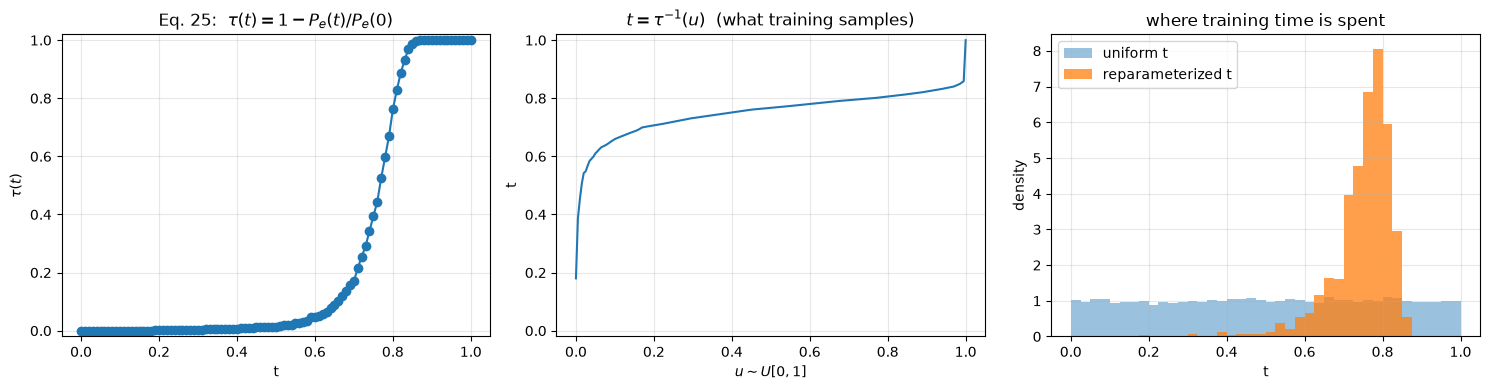

tau endpoints: tau(0)=0.000000  tau(1)=1.000000   (Eq. 25 needs 0 and 1)
|V|/(|V|-1) = 1.00084317  ==  1/P_e(0)  (the normalisation)
fraction of t below 0.65 — uniform 0.651, reparameterized 0.089
8-step generation grid: [0.18  0.673 0.719 0.746 0.767 0.784 0.799 0.818 1.   ]


In [9]:
# tau from the model-free corruption sweep: the prior, before any training. Refresh it
# later from a BinnedTokenError collected on the model itself.
tau_inverse = make_tau_inverse(ts, recovery, VOCAB_SIZE)
tau = tau_inverse.tau

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(ts, tau, marker="o")
axes[0].set_xlabel("t"); axes[0].set_ylabel(r"$\tau(t)$"); axes[0].set_ylim(-0.02, 1.02)
axes[0].set_title(r"Eq. 25:  $\tau(t) = 1 - P_e(t)/P_e(0)$"); axes[0].grid(alpha=0.3)

u_grid = np.linspace(0, 1, 201)
axes[1].plot(u_grid, tau_inverse(u_grid))
axes[1].set_xlabel(r"$u \sim U[0,1]$"); axes[1].set_ylabel("t"); axes[1].set_ylim(-0.02, 1.02)
axes[1].set_title(r"$t = \tau^{-1}(u)$  (what training samples)"); axes[1].grid(alpha=0.3)

rng = np.random.default_rng(0)
axes[2].hist(rng.random(20000), bins=40, range=(0, 1), alpha=0.45, density=True, label="uniform t")
axes[2].hist(tau_inverse(rng.random(20000)), bins=40, range=(0, 1), alpha=0.75,
             density=True, label=r"reparameterized t")
axes[2].set_xlabel("t"); axes[2].set_ylabel("density")
axes[2].set_title("where training time is spent"); axes[2].legend(); axes[2].grid(alpha=0.3)

plt.tight_layout(); plt.show()

_u = rng.random(100000)
print(f"tau endpoints: tau(0)={tau[0]:.6f}  tau(1)={tau[-1]:.6f}   (Eq. 25 needs 0 and 1)")
print(f"|V|/(|V|-1) = {VOCAB_SIZE / (VOCAB_SIZE - 1):.8f}  ==  1/P_e(0)  (the normalisation)")
print(f"fraction of t below 0.65 — uniform {np.mean(_u < 0.65):.3f}, "
      f"reparameterized {np.mean(tau_inverse(_u) < 0.65):.3f}")
print(f"8-step generation grid: {np.round(generation_grid(tau_inverse, 8), 3)}")

### Model

In [18]:
# DRAX's flow decoder, used unmodified: DDiTBlock is self-attn (RoPE) -> cross-attn to
# audio -> MLP, each sub-layer shift/scale/gated by adaLN off the time embedding. RoPE is
# applied only inside self-attention — text positions and audio frames are different
# coordinate systems, so rotating the cross-attention queries against audio keys would be
# meaningless. Licence is CC-BY-NC (Meta / aiOla): research use, keep the headers.
DENOISER_CFG = dict(
    hidden_size=MODEL_DIM,
    cond_dim=COND_DIM,
    n_heads=MODEL_HEADS,
    n_blocks=MODEL_BLOCKS,
    dropout=0.1,
    whisper_dim=1280,  # large-v3 encoder width, projected by Transformer.audio_proj
)


class AudioDecoder(nn.Module):
    """mu_psi: token distributions from audio alone, over the fixed canvas.

    The toy's version mapped audio to tokens position-by-position, which only works when
    the two are the same length. Here 1500 frames have to become CANVAS_LEN tokens with no
    alignment given, so the canvas is a set of learned queries that cross-attend into the
    latents. No time conditioning: mu depends only on audio, so there is no adaLN here.
    """

    def __init__(
        self,
        audio_dim,
        vocab_size,
        canvas_len,
        hidden=MODEL_DIM,
        n_heads=MODEL_HEADS,
        n_blocks=MU_BLOCKS,
        d_ff=4 * MODEL_DIM,
    ):
        super().__init__()
        self.queries = nn.Parameter(torch.randn(1, canvas_len, hidden) * 0.02)
        self.audio_proj = nn.Sequential(
            nn.Linear(audio_dim, hidden), nn.GELU(), nn.Linear(hidden, hidden)
        )
        self.blocks = nn.ModuleList(
            nn.ModuleDict(dict(
                n1=nn.LayerNorm(hidden),
                sa=nn.MultiheadAttention(hidden, n_heads, batch_first=True),
                n2=nn.LayerNorm(hidden),
                xa=nn.MultiheadAttention(hidden, n_heads, batch_first=True),
                n3=nn.LayerNorm(hidden),
                ff=nn.Sequential(nn.Linear(hidden, d_ff), nn.GELU(), nn.Linear(d_ff, hidden)),
            ))
            for _ in range(n_blocks)
        )
        self.norm_out = nn.LayerNorm(hidden)
        self.head = nn.Linear(hidden, vocab_size)

    def forward(self, audio):  # (B, 1500, audio_dim) -> (B, canvas_len, vocab_size)
        a = self.audio_proj(audio)
        x = self.queries.expand(audio.size(0), -1, -1)
        for b in self.blocks:
            h = b["n1"](x); x = x + b["sa"](h, h, h, need_weights=False)[0]
            h = b["n2"](x); x = x + b["xa"](h, a, a, need_weights=False)[0]
            x = x + b["ff"](b["n3"](x))
        return self.head(self.norm_out(x))


smoke_denoiser = Transformer(vocab_size=VOCAB_SIZE, masked=False, config=DENOISER_CFG).to(device)
smoke_mu_nn = AudioDecoder(audio_ds.d_model, VOCAB_SIZE, CANVAS_LEN).to(device)

for name, m in [("denoiser", smoke_denoiser), ("audio decoder", smoke_mu_nn)]:
    print(f"{name:14s} {sum(p.numel() for p in m.parameters()) / 1e6:5.1f}M params")

denoiser         5.9M params
audio decoder    2.8M params


In [22]:
def make_interpolant(x1, t, alpha_fn, beta_fn, gamma_fn=None, mu=None, stop_grad_mu=False):
    """Unchanged from the toy — it never depended on the shapes, only on 3D broadcasting."""
    x0 = torch.randn_like(x1)
    I_t = alpha_fn(t)[:, None, None] * x0 + beta_fn(t)[:, None, None] * x1
    if gamma_fn is not None and mu is not None:
        if stop_grad_mu:
            mu = mu.detach()
        I_t = I_t + gamma_fn(t)[:, None, None] * mu
    return I_t


def sequence_ce(logits, tokens):
    """(B,) cross-entropy, one value per row instead of a batch scalar.

    Its mean equals F.cross_entropy(..., reduction="mean") because every row is exactly
    CANVAS_LEN wide, so the training signal is unchanged — but keeping the per-row values
    is what lets BinnedLoss attribute a loss to the t that produced it.
    """
    B, _, vocab_size = logits.shape
    per_token = F.cross_entropy(
        logits.reshape(-1, vocab_size), tokens.reshape(-1), reduction="none"
    )
    return per_token.view(B, -1).mean(dim=1)


def flow_step(batch, denoiser, interpolant_fn, mu_nn=None, sample_t_fn=None, mu_loss_weight=None):
    """One training step, same objective as the toy's run_epoch.

    Everything stays continuous: x1 is the one-hot target read as a point on the simplex,
    x0 is Gaussian, and I_t is their interpolation. DRAX's Transformer takes that directly
    — a 3D x_t goes through `x_t @ vocab_embed.weight` instead of an embedding lookup, so
    the continuous field never has to be discretised.

    sample_t_fn maps a uniform draw to a flow time (tau^-1 from make_tau_inverse). Left
    as None, t is uniform — which at this vocabulary spends ~65% of every batch below
    t=0.65, where x_t carries nothing and the denoiser can only hear the audio.
    """
    audio = batch["audio"].to(device).float()
    tokens = batch["tokens"].to(device)
    B = tokens.size(0)
    vocab_size = denoiser.vocab_size

    x1 = F.one_hot(tokens, vocab_size).float()

    out = {}

    mu = None
    if mu_nn is not None:
        mu_logits = mu_nn(audio)
        mu = F.softmax(mu_logits, dim=-1)
        m_loss_per_seq = sequence_ce(mu_logits, tokens)
        m_loss = m_loss_per_seq.mean()
        out["mu"] = {
            "loss": m_loss.item(),
            "loss_per_seq": m_loss_per_seq,
            "pred_sequences": mu_logits.argmax(dim=-1),
        }

    u = torch.rand(B, device=device)
    t = u if sample_t_fn is None else sample_t_fn(u)
    I_t = interpolant_fn(x1=x1, t=t, mu=mu)

    logits = denoiser(x_t=I_t, time=t, audio_embeddings=audio)
    d_loss_per_seq = sequence_ce(logits, tokens)
    d_loss = d_loss_per_seq.mean()
    out["denoiser"] = {
        "loss": d_loss.item(),
        "loss_per_seq": d_loss_per_seq,
        "pred_sequences": logits.argmax(dim=-1),
    }

    loss = d_loss
    if mu_nn is not None:
        loss = loss + mu_loss_weight * m_loss

    # t comes back so the epoch loop can bin each row's loss and prediction by flow time.
    return loss, out, t


# Sanity check before wiring the loop: DRAX zero-inits the final layer, so an untrained
# denoiser is exactly uniform and its CE must equal ln(V).
smoke_interpolant_fn = partial(
    make_interpolant,
    alpha_fn=lambda t: 1 - t,
    beta_fn=lambda t: t,
)

loss, _parts, _t = flow_step(
    batch, smoke_denoiser, smoke_interpolant_fn, smoke_mu_nn, mu_loss_weight=1.0
)
print(f"denoiser CE {_parts['denoiser']['loss']:.3f}  (ln V = {np.log(VOCAB_SIZE):.3f})")
print(f"mu CE       {_parts['mu']['loss']:.3f}")
print(f"per-seq losses: {tuple(_parts['denoiser']['loss_per_seq'].shape)}")

_, _, _t_rp = flow_step(
    batch, smoke_denoiser, smoke_interpolant_fn, smoke_mu_nn,
    sample_t_fn=tau_inverse, mu_loss_weight=1.0,
)
print(f"t uniform      min {_t.min():.3f} max {_t.max():.3f}")
print(f"t reparam      min {_t_rp.min():.3f} max {_t_rp.max():.3f}")

denoiser CE 7.079  (ln V = 7.079)
mu CE       7.094
per-seq losses: (32,)
t uniform      min 0.015 max 0.974
t reparam      min 0.539 max 0.849


### Training

Draft loop, same shape as the toy's `run_epoch`: trains when given an optimizer, evaluates
otherwise. WER is binned over `t` with `BinnedWER`, so a run is tracked across flow times
rather than collapsed into one number — but note it scores the x1-prediction at a random
`t`, not a real decode, so it is a lower bound on what a sampler would produce.

In [23]:
def run_epoch(loader, denoiser, interpolant_fn, mu_nn=None, optimizer=None,
              scheduler=None, max_grad_norm=1.0, log_every=100,
              loss_bins=10, wer_bins=10, sample_t_fn=None, mu_loss_weight=None):
    """One pass over `loader`. Trains if `optimizer` is given, evaluates otherwise.

    Binned metrics per model, all keyed on the flow time t:
      *_loss_binned   cross-entropy per bin       — free, leave on
      *_perr_binned   token error P_e per bin     — free, and what refreshes tau
      *_wer_binned    WER per bin                 — needs a decode per batch, opt-out

    loss_bins drives the first two; wer_bins the third. Set either to 0 to skip.

    sample_t_fn is passed through to flow_step. Use the SAME one for train and eval, or
    the two are not measuring the same distribution of t.
    """
    train_mode = optimizer is not None
    denoiser.train(train_mode)
    if mu_nn is not None:
        mu_nn.train(train_mode)

    params = list(denoiser.parameters())
    if mu_nn is not None:
        params += list(mu_nn.parameters())

    names = ["denoiser"] + (["mu"] if mu_nn is not None else [])
    losses = {n: BinnedLoss(loss_bins).to(device) for n in names} if loss_bins else {}
    perrs = {n: BinnedTokenError(loss_bins).to(device) for n in names} if loss_bins else {}
    wers = {n: BinnedWER(tokenizer, PAD_ID, num_bins=wer_bins).to(device)
            for n in names} if wer_bins else {}

    totals, n_seqs = defaultdict(float), 0
    t_start = time.time()

    ctx = torch.enable_grad() if train_mode else torch.no_grad()
    with ctx:
        for step, batch in enumerate(loader):
            loss, out, t = flow_step(batch, denoiser, interpolant_fn, mu_nn,
                                    sample_t_fn=sample_t_fn, mu_loss_weight=mu_loss_weight)

            if train_mode:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(params, max_norm=max_grad_norm)
                optimizer.step()
                if scheduler is not None:
                    scheduler.step()
                # set_to_none frees the grad buffers — worth it when the vocab is 51,866
                optimizer.zero_grad(set_to_none=True)

            tokens = batch["tokens"].to(device)
            B = tokens.size(0)
            totals["loss"] += loss.item() * B
            for name in names:
                totals[f"{name}_loss"] += out[name]["loss"] * B
                preds = out[name]["pred_sequences"]
                if name in losses:
                    losses[name].update(out[name]["loss_per_seq"], t)
                    perrs[name].update(preds, tokens, t)
                if name in wers:
                    wers[name].update(preds, tokens, t)
            n_seqs += B

            if log_every and train_mode and step % log_every == 0:
                print(f"    step {step:5d}  loss {loss.item():7.3f}", end="\r", flush=True)

    result = {k: v / n_seqs for k, v in totals.items()}
    result["seconds"] = time.time() - t_start
    for name, m in losses.items():
        result[f"{name}_loss_binned"] = m
    for name, m in perrs.items():
        result[f"{name}_perr_binned"] = m
    for name, m in wers.items():
        result[f"{name}_wer"] = m.overall()
        result[f"{name}_wer_binned"] = m
    return result


def fit(num_epochs, train_loader, val_loader, denoiser, interpolant_fn,
        mu_nn=None, optimizer=None, scheduler=None, mu_loss_weight=None,
        train_wer_bins=0, val_wer_bins=10, loss_bins=10, sample_t_fn=None):
    """Draft driver. No checkpointing or early stopping yet — add as needed.

    train_wer_bins defaults to 0: decoding every training batch to text roughly doubles
    the step cost. Loss and P_e binning stay on for both splits because they are free.
    """
    history = {"train": [], "val": []}
    for epoch in range(num_epochs):
        tr = run_epoch(train_loader, denoiser, interpolant_fn, mu_nn,
                       optimizer=optimizer, scheduler=scheduler,
                       loss_bins=loss_bins, wer_bins=train_wer_bins,
                       sample_t_fn=sample_t_fn, mu_loss_weight=mu_loss_weight)
        va = run_epoch(val_loader, denoiser, interpolant_fn, mu_nn,
                       loss_bins=loss_bins, wer_bins=val_wer_bins,
                       sample_t_fn=sample_t_fn, mu_loss_weight=mu_loss_weight)
        history["train"].append(tr)
        history["val"].append(va)

        line = (f"epoch {epoch + 1:3d}/{num_epochs}  {tr['seconds']:5.0f}s"
                f" | train loss {tr['loss']:6.3f} | val loss {va['loss']:6.3f}")
        if "denoiser_wer" in va:
            line += f" | val WER {va['denoiser_wer']:6.2f}%"
        print(line)
    return history


def refresh_tau(history, vocab_size, split="val", name="denoiser", epoch=-1,
                min_recovery=0.05):
    """Re-derive tau^-1 from the model's own P_e instead of the corruption prior.

    The sweep's tau is what the interpolant does to a target with no model involved. Once
    the denoiser can read the audio it recovers tokens the corrupted field alone could
    not, so its P_e curve — and the schedule that should follow from it — moves left.
    Bins with no samples are dropped; under an existing reparameterization the low-t bins
    are empty by construction.
    """
    m = history[split][epoch][f"{name}_perr_binned"]
    seen = (m.count > 0).cpu().numpy()
    ts_seen = m.bin_centers().numpy()[seen]
    rec_seen = m.recovery().cpu().numpy()[seen]
    if rec_seen.size == 0 or rec_seen.max() < min_recovery:
        raise ValueError(
            f"{name} recovers at most {rec_seen.max() if rec_seen.size else 0:.3f} of tokens "
            f"in any bin.\nP_e is flat at 1, so tau would be 0 everywhere and the schedule "
            f"would collapse onto t=1.\nTrain further before refreshing, or lower "
            f"min_recovery if that is deliberate."
        )
    # tau is defined on [0, 1]; pin the endpoints so the inverse stays total.
    ts_full = np.concatenate([[0.0], ts_seen, [1.0]])
    rec_full = np.concatenate([[1.0 / vocab_size], rec_seen, [1.0]])
    return make_tau_inverse(ts_full, rec_full, vocab_size)


def plot_evolution(history, key, split="val", name="denoiser", ax=None):
    """One line per epoch, shaded oldest to newest — the toy's plot_validity_evolution.

    key is "loss", "wer" or "perr".
    """
    denom = {"loss": "count", "wer": "ref_words", "perr": "count"}[key]
    ylabel = {"loss": "cross-entropy", "wer": "WER %", "perr": r"$P_e$"}[key]
    ax = ax or plt.subplots(figsize=(6, 4))[1]
    epochs = history[split]
    for i, epoch in enumerate(epochs):
        m = epoch.get(f"{name}_{key}_binned")
        if m is None:
            continue
        centers = ((m.bin_edges()[:-1] + m.bin_edges()[1:]) / 2).numpy()
        seen = (getattr(m, denom) > 0).cpu().numpy()
        ax.plot(centers[seen], m.compute().cpu().numpy()[seen], marker="o",
                color=plt.cm.viridis(i / max(len(epochs) - 1, 1)), label=f"epoch {i + 1}")
    ax.set_xlabel("t (binned)")
    ax.set_ylabel(ylabel)
    ax.set_ylim(bottom=0, top={"loss": None, "wer": 105, "perr": 1.02}[key])
    ax.set_title(f"{split} {key} across t — {name}")
    ax.grid(alpha=0.3); ax.legend(fontsize=7, ncol=2)
    return ax

### Split the Data

In [ ]:
VAL_FRACTION = 0.05
SPLIT_SEED = 0

train_ds, val_ds = random_split(
    work_ds,
    [1 - VAL_FRACTION, VAL_FRACTION],
    generator=torch.Generator().manual_seed(SPLIT_SEED),
)


def make_loader(ds, shuffle):
    return DataLoader(
        ds, batch_size=BS, shuffle=shuffle, num_workers=4,
        collate_fn=collate_fn, pin_memory=(device.type == "cuda"),
        drop_last=shuffle,  # keeps the step count exact for the scheduler
    )

train_loader, val_loader = make_loader(train_ds, True), make_loader(val_ds, False)
print(f"train {len(train_ds)} utts / {len(train_loader)} steps  |  val {len(val_ds)}")

train 1900 utts / 59 steps  |  val 100


### Linear Interpolant Variant

epoch   1/50     14s | train loss  5.954 | val loss  4.851 | val WER 100.00%
epoch   2/50     10s | train loss  4.856 | val loss  4.656 | val WER 100.00%
epoch   3/50     11s | train loss  4.508 | val loss  3.989 | val WER 100.98%
epoch   4/50     11s | train loss  3.854 | val loss  3.396 | val WER  99.60%
epoch   5/50     11s | train loss  3.510 | val loss  3.259 | val WER  99.88%
epoch   6/50     10s | train loss  3.354 | val loss  3.212 | val WER  99.39%
epoch   7/50      8s | train loss  3.171 | val loss  2.949 | val WER  96.10%
epoch   8/50     10s | train loss  3.016 | val loss  2.799 | val WER  94.45%
epoch   9/50     10s | train loss  2.882 | val loss  2.646 | val WER  92.28%
epoch  10/50      9s | train loss  2.816 | val loss  2.650 | val WER  90.33%
epoch  11/50      9s | train loss  2.681 | val loss  2.578 | val WER  90.21%
epoch  12/50     10s | train loss  2.640 | val loss  2.485 | val WER  92.50%
epoch  13/50      8s | train loss  2.551 | val loss  2.537 | val WER  87.68%

/tmp/ipykernel_8280/1752688199.py:153: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.grid(alpha=0.3); ax.legend(fontsize=7, ncol=2)


<Axes: title={'center': 'train wer across t — denoiser'}, xlabel='t (binned)', ylabel='WER %'>

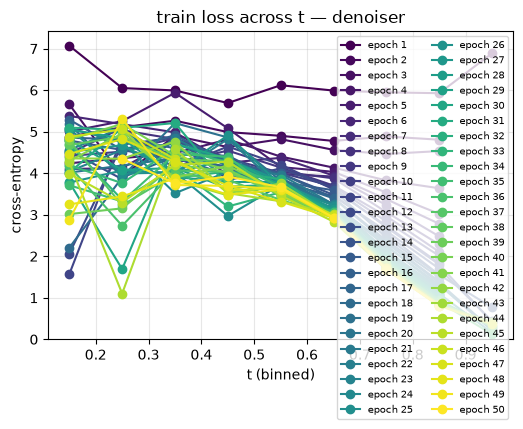

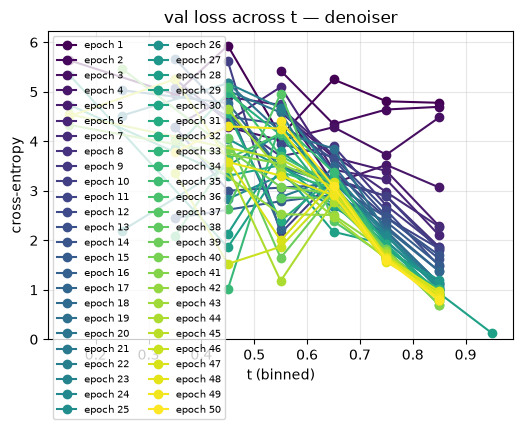

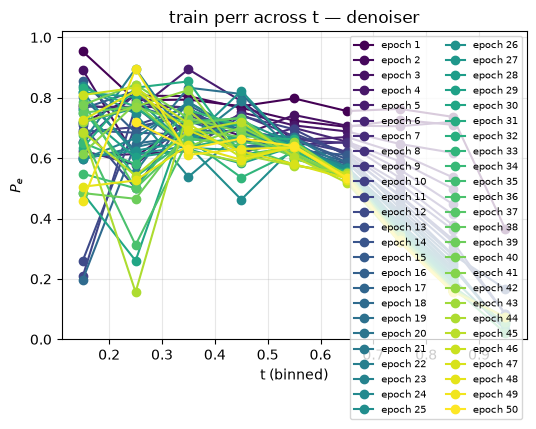

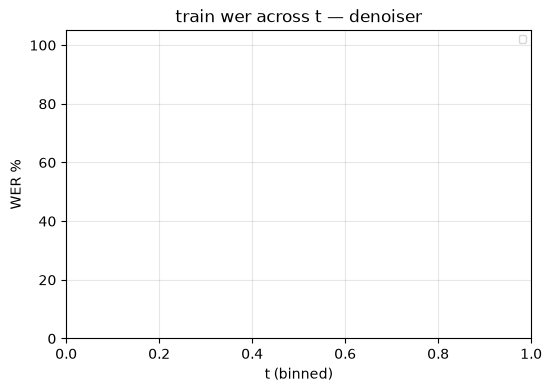

In [29]:
NUM_EPOCHS = 50
DENOISER_LR = 1e-2

denoiser = Transformer(vocab_size=VOCAB_SIZE, masked=False, config=DENOISER_CFG).to(device)
optimizer = torch.optim.AdamW([
    {"params": denoiser.parameters(), "lr": DENOISER_LR},
])
steps_per_epoch = len(train_loader)
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer,
    max_lr=DENOISER_LR,
    total_steps=steps_per_epoch * NUM_EPOCHS,
)

interpolant_fn = partial(
    make_interpolant,
    alpha_fn=lambda t: 1 - t,
    beta_fn=lambda t: t,
)

history = fit(
    NUM_EPOCHS,
    train_loader,
    val_loader,
    denoiser,
    interpolant_fn,
    optimizer=optimizer,
    scheduler=scheduler,
    sample_t_fn=tau_inverse,
)

plot_evolution(history, "loss", split="train", name="denoiser")
plot_evolution(history, "loss", split="val", name="denoiser")
plot_evolution(history, "perr", split="train", name="denoiser")
plot_evolution(history, "wer", split="train", name="denoiser")

### Train Audio-Conditioned Variant

In [ ]:
NUM_EPOCHS = 50
DENOISER_LR = 1e-2
AUDIO_DECODER_LR = 1e-2
STOP_GRAD_MU = True
MU_LOSS_WEIGHT = 1.0

denoiser = Transformer(vocab_size=VOCAB_SIZE, masked=False, config=DENOISER_CFG).to(device)
mu_nn = AudioDecoder(audio_ds.d_model, VOCAB_SIZE, CANVAS_LEN).to(device)

optimizer = torch.optim.AdamW([
    {"params": denoiser.parameters(), "lr": DENOISER_LR},
    {"params": mu_nn.parameters(), "lr": AUDIO_DECODER_LR},
])
steps_per_epoch = len(train_loader)
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer,
    max_lr=[DENOISER_LR, AUDIO_DECODER_LR],
    total_steps=steps_per_epoch * NUM_EPOCHS,
)

interpolant_fn = partial(
    make_interpolant,
    alpha_fn=lambda t: 1 - t,
    beta_fn=lambda t: t,
    gamma_fn=lambda t: 1 - t,
    stop_grad_mu=STOP_GRAD_MU
)

history = fit(
    NUM_EPOCHS,
    train_loader,
    val_loader,
    denoiser,
    interpolant_fn,
    mu_nn=mu_nn,
    mu_loss_weight=MU_LOSS_WEIGHT,
    optimizer=optimizer,
    scheduler=scheduler,
    sample_t_fn=tau_inverse,
)

plot_evolution(history, "loss", split="train", name="denoiser")
plot_evolution(history, "loss", split="val", name="denoiser")
plot_evolution(history, "perr", split="train", name="denoiser")
plot_evolution(history, "wer", split="train", name="denoiser")

### Three-term Endpoint

In [ ]:
NUM_EPOCHS = 50
DENOISER_LR = 1e-2
AUDIO_DECODER_LR = 1e-2
STOP_GRAD_MU = True
MU_LOSS_WEIGHT = 1.0
# Make it peak at 0.5
C = 0.5

denoiser = Transformer(vocab_size=VOCAB_SIZE, masked=False, config=DENOISER_CFG).to(device)
mu_nn = AudioDecoder(audio_ds.d_model, VOCAB_SIZE, CANVAS_LEN).to(device)

optimizer = torch.optim.AdamW([
    {"params": denoiser.parameters(), "lr": DENOISER_LR},
    {"params": mu_nn.parameters(), "lr": AUDIO_DECODER_LR},
])
steps_per_epoch = len(train_loader)
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer,
    max_lr=[DENOISER_LR, AUDIO_DECODER_LR],
    total_steps=steps_per_epoch * NUM_EPOCHS,
)

interpolant_fn = partial(
    make_interpolant,
    alpha_fn=lambda t: 1 - t,
    beta_fn=lambda t: t,
    gamma_fn=lambda t: 4 * C * t * (1 - t),
    stop_grad_mu=STOP_GRAD_MU
)

history = fit(
    NUM_EPOCHS,
    train_loader,
    val_loader,
    denoiser,
    interpolant_fn,
    mu_nn=mu_nn,
    mu_loss_weight=MU_LOSS_WEIGHT,
    optimizer=optimizer,
    scheduler=scheduler,
    sample_t_fn=tau_inverse,
)

plot_evolution(history, "loss", split="train", name="denoiser")
plot_evolution(history, "loss", split="val", name="denoiser")
plot_evolution(history, "perr", split="train", name="denoiser")
plot_evolution(history, "wer", split="train", name="denoiser")